# ShootArchitecture: Adel's wheat shoots in metafspm

ShootArchitecture (`openalea.adel.architecture`) is the port of Adel's shoot architecture (its `AdelDyn`) to a metafspm
`StructuralComponent`:
- the plants' topology in metafspm's MPG: axes, phytomers, organs, elements;
- the organs' dimensions and leaf shapes, read from Adel's tables;
- the elements derived from the organs' lengths;
- their placement by Adel's turtle and their triangles, for light models and display.

It does not decide how the organs grow. Development and senescence models write the organs' lengths, as cnwgrass
writes them to `AdelDyn` in Wheat-BRIDGES. This tutorial uses `ScenarioDevelopment` (`openalea.adel.development`), a
small component that gives the lengths from a simple deterministic scenario.

The steps:
0. reading the code: metafspm's component formalism, on ShootArchitecture;
1. Adel's tables, plants from a few numbers, and a canopy of 20 plants;
2. growing it, and reading its structure;
3. drawing the canopy;
4. the tillers: their emergence, insertion and inclination;
5. the coupling contract: what development models write, and what light models read;
6. the comparison with the legacy, and the speed.

Lengths are in m, thermal time in °Cd.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from dataclasses import replace

from openalea.adel.development import (TRANSLATOR, ScenarioShoot, coleoptile_sowing_depth, random_delays, shoot_scene,
                                       sown_stand)
from openalea.adel.display import state_colors
from openalea.adel.leaf_shapes import LeafShapes
from openalea.adel.tables import sample_tables, wheat_tables
from openalea.metafspm.display import draw, value_colors
from openalea.metafspm.scene.population import planting
from openalea.metafspm.scene.scene import Scene

## 0. Reading the code: metafspm's component formalism

`ShootArchitecture` is a metafspm `StructuralComponent`. All the ported models are written in the same form; this section presents it on
`ShootArchitecture`, so that its code (`openalea.adel.architecture`) can be read. For more, metafspm's tutorial `examples/soil_plant_atmosphere/tutorial_fspm2026_general_usage.ipynb` (in the metafspm repository) builds components step by step; its user guide `docs/user.md` describes each part.

- **A component is a dataclass.** Its fields declare its variables:
  - `input_variable`: written by another model (`by`), read here;
  - `state_variable`: computed by this component;
  - `parameter`: a constant, which may differ between plants.

  Each declaration documents its variable (`unit`, `description`) and places it at a **scale** of the plant graph
  (MPG: Plant, Axis, GrowthUnit, Phytomer, Organ, SubOrgan for the elements; Compartment and Connection for
  anatomies).
- **Its processes are steps:** methods decorated by their place in the schedule. `@rate` and `@state` are for the
  processes of a fixed structure. `@potential`, `@actual`, `@segmentation` and `@postsegmentation` are the growth
  rows: before, while and after the structure changes. A step's arguments are variables, named as declared. Each
  comes as a whole array, one value per entity of its scale, for every plant at once. A step returns its output,
  named after the method, or several outputs as a dict `{name: values}`.
- **A `StructuralComponent` builds and changes the structure.** `initiate_plant` builds each plant's main stem and first phytomer in the MPG. Its segmentation step `_axis_phytomers` creates the axes and phytomers that development asks for, by returning a `NewNodes` (each phytomer with its organs and elements, its dimensions from the tables). Its postsegmentation steps then derive the elements from the organs' lengths, incline the tillers and place the elements. `ScenarioDevelopment`, a `FunctionalComponent`, writes its inputs.
- **The values live in the DataStructure**, one array per variable: `ds.get(name)`, `ds.set(name, values)`.
  `ds.entity_ids(scale)` lists the entities and `ds.owner(scale)` gives each node's entity at a coarser scale. The
  MPG holds the topology, read through `ds.structure`.
- **A plant model is a `CompositeModel`.** Its `initiators` build each plant, it creates its components on the
  plants' DataStructure, and a **translator** states which component provides each input. A `Scene` builds the
  plants from a planting table (one row per plant, with its scenario, whose `parameters` set the components'
  parameters) and runs the models step by step.

`ShootArchitecture.declarations()` lists what the component declares:

In [2]:
from openalea.adel.architecture import ShootArchitecture

declarations = ShootArchitecture.declarations()
print(declarations["kind"].value_counts().to_string())
declarations.loc[declarations["kind"] == "input", ["name", "scale", "unit", "description", "by"]]

kind
state_variable    46
parameter         16
input             10


,name,scale,unit,description,by
0,axis_number,Plant,adim,"The number of the plant's axes emerged, in its...",model_development
1,phytomer_number,Axis,adim,The number of phytomers the axis has (its deve...,model_development
2,organ_length,Organ,m,The organ's length,model_development
3,visible_length,Organ,m,The organ's length out of the sheaths' tube,model_development
4,rolled_length,Organ,m,The blade's rolled length in the sheaths' tube,model_development
5,organ_senesced_length,Organ,m,The organ's senesced length,model_senescence
6,age,Organ,°Cd,The blade's age (its shape class when the data...,model_development
7,haun_stage,Axis,adim,The axis' Haun stage (its tillers' inclination...,model_development
8,shape_mature_length,Organ,m,"The blade's final length, its shape's length",model_development
9,shape_max_width,Organ,m,"The blade's maximal width, its shape's width",model_development


`ShootArchitecture.schedule()` gives its steps in the order they run, grouped by their place in the schedule:

In [3]:
for stages, steps in ShootArchitecture.schedule():
    print(f"{', '.join(stages):>18}  {', '.join(steps)}")

      segmentation  _axis_phytomers
  postsegmentation  _elements, _inclination, _placement


A step, `_placement`, as written in the code: its arguments are the variables it reads, its
return the variables it writes.

In [4]:
import inspect

print(inspect.getsource(ShootArchitecture._placement))

    @postsegmentation
    def _placement(self, length, rolled_part, inclination, organ_azimuth, axis_azimuth, bearer_row,
                   phytomer_rank) -> dict:
        """The elements' placement, their frames by Adel's turtle (turtle.interpret): each one's base, heading and up
        where it is drawn, and its end; from its plant's position and rotation, on the elements' lengths."""
        ds = self.data_structure
        g = ds.structure
        element_kind, organ_kind = self._kinds()
        order, frame_source, plant_base = self._traversal()
        organ, axis = np.asarray(ds.owner("Organ")), np.asarray(ds.owner("Axis"))
        plant, phytomer = np.asarray(ds.owner("Plant")), np.asarray(ds.owner("Phytomer"))
        plants = ds.entity_ids("Plant").tolist()
        plant_position = np.array([[g.property(name).get(v, 0.) for name in ("x", "y", "z")] for v in plants],
                                  dtype=float).reshape(-1, 3)
        plant_rotation = np.array([g.property("

## 1. Adel's tables and a canopy

ShootArchitecture reads Adel's two tables, with lengths in cm:
- the **axes table** (Adel's `axeT`): one row per axis of each plant, with its final leaf number `nf` and its first
  leaf's emergence `emf1` (°Cd);
- the **phytomer table** (Adel's `phytoT`): one row per axis and rank, with the blade's length `Ll` and width `Lw`, the
  sheath's `Gl`, `Gd`, the internode's `El`, `Ed`, and the leaf shape's indices `Lindex`, `Lseed`.

Without tables, ShootArchitecture uses Adel's sample plant (`openalea.adel.tables.sample_tables`): a main stem and
four tillers (T1 to T4). Each tiller takes the main stem's ranks, 0.9 times.

In [5]:
axes_table, phytomer_table = sample_tables()
axes_table[["plant", "axe", "nf", "emf1", "HS_final", "incT", "dredT"]]

,plant,axe,nf,emf1,HS_final,incT,dredT
0,1,MS,12.0,21.543097,12.0,1.599404,0.000000
1,1,T1,9.0,161.522819,NaN,60.279137,4.124880
2,1,T2,8.0,256.091716,NaN,60.706547,4.433841
3,1,T3,7.0,327.074709,NaN,58.083629,2.075207
4,1,T4,6.0,424.385645,NaN,60.417345,1.590662


In [6]:
phytomer_table.loc[phytomer_table["axe"] == "MS", ["axe", "n", "Ll", "Lw", "Gl", "Gd", "El", "Ed", "Lindex", "Lseed"]]

,axe,n,Ll,Lw,Gl,Gd,El,Ed,Lindex,Lseed
0,MS,1,9.733180,0.459954,2.228428,0.183662,0.000000,0.000000,6.0,85.0
1,MS,2,8.256204,0.444063,2.334653,0.199892,0.000000,0.000000,6.0,47.0
2,MS,3,6.822363,0.426528,2.494112,0.215413,0.000000,0.000000,6.0,38.0
3,MS,4,6.502344,0.431675,2.787851,0.231162,0.000000,0.000000,6.0,114.0
4,MS,5,7.452413,0.491038,3.502955,0.248718,0.000000,0.000000,6.0,16.0
5,MS,6,9.265873,0.620232,4.977466,0.261250,0.000000,0.000000,6.0,104.0
6,MS,7,11.881087,0.811207,7.112362,0.271246,0.000000,0.000000,6.0,61.0
7,MS,8,14.954656,1.031545,9.232181,0.292957,1.266667,0.023794,5.0,13.0
8,MS,9,17.508110,1.234782,10.620333,0.330251,4.850000,0.091105,4.0,11.0
9,MS,10,18.939615,1.389160,11.279239,0.357112,8.666667,0.162799,3.0,33.0


A plant can also be generated from a few numbers, without tables. Its per-plant parameters are `leaf_number`,
`tiller_number`, `longest_blade_length` and `longest_blade_width`. Its dimensions follow Adel's reference profiles
along the main stem (plantgen's WheatDimensions), scaled to its longest blade
(`openalea.adel.tables.wheat_tables`):

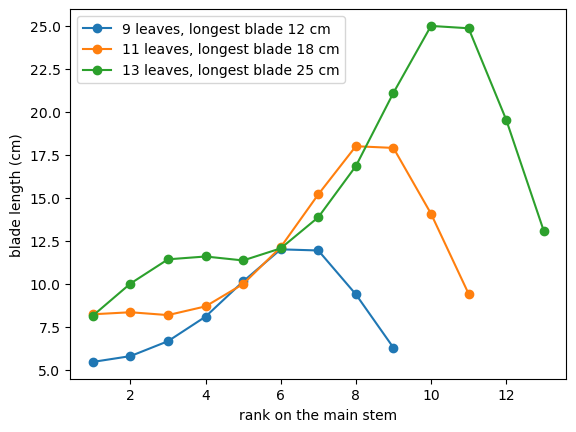

In [7]:
for leaf_number, length in ((9, 0.12), (11, 0.18), (13, 0.25)):
    _, generated = wheat_tables(leaf_number=leaf_number, tiller_number=2, longest_blade_length=length,
                                longest_blade_width=0.015)
    main = generated.loc[generated["axe"] == "MS"]
    plt.plot(main["n"], main["Ll"], "o-", label=f"{leaf_number} leaves, longest blade {length * 100:.0f} cm")
plt.xlabel("rank on the main stem")
plt.ylabel("blade length (cm)")
plt.legend();

In a scene, each plant gets its own parameters, for instance
`shoot_scene(plants, plant_parameters=[dict(leaf_number=9), dict(leaf_number=13)])`. Plants with the same numbers share
their tables. `example/generated_plants.py` grows three such plants.

A metafspm scene starts from a planting table: one row per plant, with its plant model, its position (m), its rotation
(°) and its scenario's parameters. metafspm's `planting()` writes it from given plants (`Planting(x, y, z, rotation)`;
z is minus the sowing depth), with parameters shared by every plant and per-plant ones. (`shoot_scene` builds this
table for you; here it is written out.)

The plant model `ScenarioShoot` is a `CompositeModel`: it runs `ScenarioDevelopment` and then ShootArchitecture, and its
translator states the coupling contract, which component provides each input:

In [8]:
pd.DataFrame([dict(receiver=link.receiver, variable=link.variable, provider=link.provider) for link in TRANSLATOR.links])

,receiver,variable,provider
0,ShootArchitecture,axis_number,ScenarioDevelopment
1,ShootArchitecture,phytomer_number,ScenarioDevelopment
2,ShootArchitecture,haun_stage,ScenarioDevelopment
3,ShootArchitecture,organ_length,ScenarioDevelopment
4,ShootArchitecture,visible_length,ScenarioDevelopment
5,ShootArchitecture,organ_senesced_length,ScenarioDevelopment
6,ShootArchitecture,age,ScenarioDevelopment
7,ScenarioDevelopment,axis_row,ShootArchitecture
8,ScenarioDevelopment,organ_rank,ShootArchitecture


The 20 plants are sown in four rows 15 cm apart, with random rotations. Each is sown at 0.9 times its coleoptile's
length, so that the coleoptile's tip emerges, and given a random delay of up to 60 °Cd in its development. The leaf
shapes are echap's, which change with the blade's age. They are fitted once and shared by every plant. With these
dynamic shapes, the sample plant's shape classes follow echap's rule.

In [9]:
shared = dict(leaves=LeafShapes.echap(xy_model="Soissons_byleafclass"), n_sect=2, thermal_time_step=10.)
depth = coleoptile_sowing_depth(shared)
stand = [replace(plant, z=-depth) for plant in sown_stand(20, n_rows=4, row_spacing=0.15, plant_spacing=0.04, seed=0)]
table = planting(stand, ScenarioShoot, parameters=shared,
                 plant_parameters=[{"delay": delay} for delay in random_delays(20, max_delay=60., seed=0)])
scene = Scene(table, time_step=3600)
ds = scene.populations[0].data_structure
architecture = scene.populations[0].instance.architecture
print(f"sown at {depth * 100:.2f} cm")
table[["plant", "x", "y", "z", "rotation"]].head()

sown at 2.01 cm


,plant,x,y,z,rotation
0,p0,0.000629,-0.000661,-0.020056,14.750469
1,p1,0.040525,-0.002678,-0.020056,328.592008
2,p2,0.086520,0.004735,-0.020056,195.704997
3,p3,0.113673,-0.003116,-0.020056,0.985860
4,p4,0.148375,-0.001094,-0.020056,262.675961


## 2. Growing the canopy

Each `scene.run()` is one call of each component. `ScenarioDevelopment` advances each plant's thermal time by
`thermal_time_step` (10 °Cd), and writes:
- the number of axes emerged per plant;
- the number of phytomers per axis;
- each organ's length, visible length and senesced length, and each blade's age.

ShootArchitecture then creates the phytomers asked for, derives the elements and places them.

In [10]:
snapshots, history = {}, []
for step in range(121):
    scene.run()
    history.append(dict(thermal_time=step * 10., organs=len(ds.entity_ids("Organ")), elements=ds.n_nodes(),
                        green_area=np.sum(ds.get("green_area")), senesced_area=np.sum(ds.get("senesced_area"))))
    if step in (40, 80, 120):
        snapshots[step] = (architecture.triangles(), np.asarray(ds.get("is_green")).copy())
history = pd.DataFrame(history)
history.iloc[::20]

,thermal_time,organs,elements,green_area,senesced_area
0,0.0,60,140,0.000000,0.000000
20,200.0,201,469,0.011266,0.000000
40,400.0,654,1526,0.037401,0.000000
60,600.0,1332,3108,0.075109,0.002915
80,800.0,2001,4669,0.111733,0.020051
100,1000.0,2481,5789,0.173848,0.052675
120,1200.0,2520,5880,0.180747,0.098949


The structure is in the MPG: Plant, then Axis, GrowthUnit, Phytomer, Organ (StemInternode, Sheath, Blade), and
SubOrgan, the elements. Each organ has a hidden element and visible ones; a blade has `n_sect` of these (here 2).
The variables are arrays on the DataStructure, one value per entity of their scale.

Here are the organs of the first plant's main stem:

In [11]:
first_plant = ds.map_to(np.arange(len(ds.entity_ids("Plant")), dtype=float), "Plant", "Organ", "broadcast") == 0
main_stem = ds.map_to((np.asarray(ds.get("bearer_row")) < 0).astype(float), "Axis", "Organ", "broadcast") > 0
organs = pd.DataFrame({name: np.asarray(ds.get(name)) for name in
                       ("organ_rank", "organ_length", "visible_length", "organ_senesced_length", "organ_area",
                        "shape_mature_length", "shape_max_width")})
organs.insert(0, "organ", architecture.organ_names())
organs[first_plant & main_stem].sort_values(["organ_rank", "organ"]).head(12)

,organ,organ_rank,organ_length,visible_length,organ_senesced_length,organ_area,shape_mature_length,shape_max_width
2,blade,1,0.097332,0.097332,0.097332,0.000355,0.097332,0.004600
0,internode,1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,sheath,1,0.022284,0.022284,0.000000,0.000129,0.000000,0.000000
86,blade,2,0.082562,0.060278,0.082562,0.000199,0.082562,0.004441
84,internode,2,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
85,sheath,2,0.023347,0.001062,0.000000,0.000007,0.000000,0.000000
206,blade,3,0.068224,0.044877,0.068224,0.000137,0.068224,0.004265
204,internode,3,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
205,sheath,3,0.024941,0.001595,0.000000,0.000011,0.000000,0.000000
392,blade,4,0.065023,0.040082,0.065023,0.000121,0.065023,0.004317


## 3. Drawing the canopy

`architecture.triangles()` gives every triangle of the canopy, as metafspm's `Triangles`:
- `vertices`, shape (T, 3, 3), in the scene's frame, in m;
- `owner`, shape (T,), the node index of the element each triangle belongs to.

Stem elements are drawn as slim cylinders. A blade element is drawn as its rolled part's cylinder, then its flat
part's mesh, made from its leaf shape. `openalea.adel.display` draws them with matplotlib, without PlantGL, coloured
here by each element's state: green, or straw when more senesced than green.

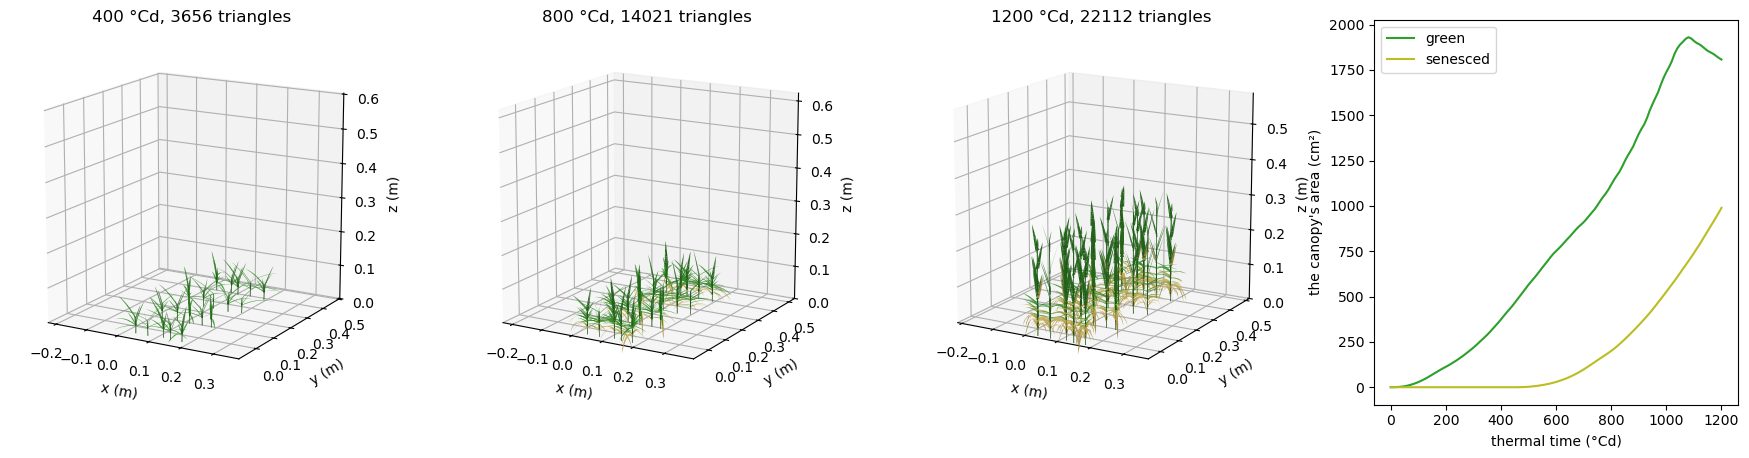

In [12]:
figure = plt.figure(figsize=(18, 5))
for k, (step, (triangles, is_green)) in enumerate(snapshots.items()):
    axes = figure.add_subplot(1, 4, k + 1, projection="3d")
    draw(axes, triangles, colors=state_colors(is_green))
    axes.set_title(f"{step * 10:.0f} °Cd, {len(triangles)} triangles")
axes = figure.add_subplot(1, 4, 4)
axes.plot(history["thermal_time"], history["green_area"] * 1e4, color="tab:green", label="green")
axes.plot(history["thermal_time"], history["senesced_area"] * 1e4, color="tab:olive", label="senesced")
axes.set_xlabel("thermal time (°Cd)")
axes.set_ylabel("the canopy's area (cm²)")
axes.legend()
figure.subplots_adjust(left=0.02, right=0.98, wspace=0.25)

## 4. The tillers

Each plant has a main stem (MS) and up to four tillers (T1 to T4), one per row of its axes table. A tiller appears when
its development asks for it: ScenarioDevelopment counts the axes whose first leaf has appeared (the table's `emf1`).
It is inserted on its bearer's phytomer: T1 on the main stem's first, T2 on its second, and T1.2 would be on T1's
second. Here are the first plant's axes at the end:

In [13]:
axes_of = ds.map_to(np.arange(len(ds.entity_ids("Plant")), dtype=float), "Plant", "Axis", "broadcast") == 0
population_axes = architecture.tables()[0]            # the population's axes table, which axis_row indexes
pd.DataFrame(dict(axis=architecture.axis_names(), insertion_rank=np.asarray(ds.get("insertion_rank")),
                  first_leaf=population_axes["emf1"].to_numpy()[np.asarray(ds.get("axis_row"))],
                  phytomers=np.asarray(ds.get("axis_phytomers")), haun_stage=np.asarray(ds.get("haun_stage")),
                  final_leaf_number=np.asarray(ds.get("final_leaf_number"))))[axes_of].reset_index(drop=True)

,axis,insertion_rank,first_leaf,phytomers,haun_stage,final_leaf_number
0,MS,0,21.543097,12,12.0,12
1,T1,1,161.522819,9,9.0,9
2,T2,2,256.091716,8,8.0,8
3,T3,3,327.074709,7,7.0,7
4,T4,4,424.385645,6,6.0,6


AdelDyn draws every axis vertical (all its inclinations are 0), and so does ShootArchitecture by default, to stay
comparable with it. The canopy above is drawn that way: the tillers grow inside the main stem.

With the parameter `tiller_inclination=1`, ShootArchitecture inclines the axes by static Adel's rules (Adel.R's
getIncT and axe_inclination), from the axes table:
- `azTb`: the tiller's insertion azimuth; `azT`: its first phytomer's azimuth;
- `incT`: its first internode's inclination. It ramps with the tiller's Haun stage (`haun_stage`, an input written
  by development): 3° until stage 1, then 30° per stage, up to incT;
- `dredT`: the straightening distance. Where the inclined stem reaches dredT horizontally from its insertion, its
  stem element is bent so that its end falls there, and the next one is turned back to the vertical.

Here is one plant grown both ways, coloured by axis:

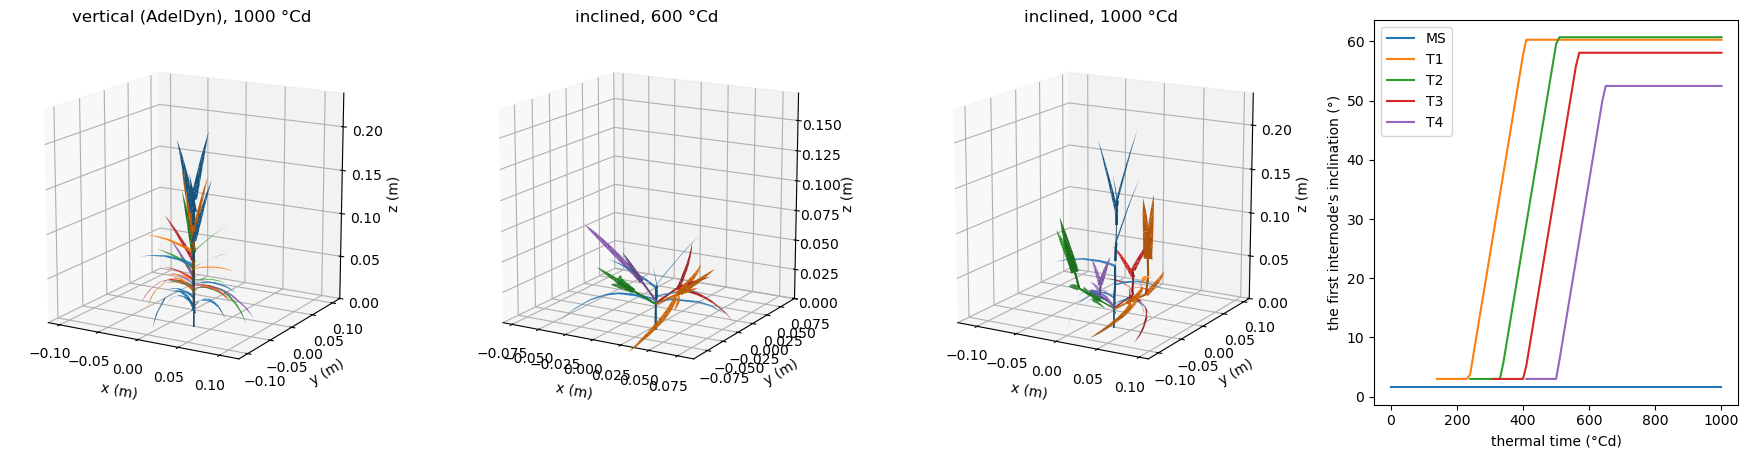

In [14]:
from matplotlib import colormaps

def one_plant(tiller_inclination, n_steps=100):
    plant = shoot_scene(leaves=shared["leaves"], n_sect=2, tiller_inclination=tiller_inclination)
    plant_architecture = plant.populations[0].instance.architecture
    plant_ds = plant.populations[0].data_structure
    snapshots, inclinations = {}, []
    for step in range(n_steps + 1):
        plant.run()
        first_internodes = ((plant_architecture.organ_names() == "internode")
                            & (np.asarray(plant_ds.get("organ_rank")) == 1))
        axis_of = plant_ds.map_to(np.arange(len(plant_ds.entity_ids("Axis")), dtype=float), "Axis", "Organ",
                                  "broadcast")[first_internodes].astype(int)
        inclinations.append(dict(zip(plant_architecture.axis_names()[axis_of],
                                     np.asarray(plant_ds.get("inclination"))[first_internodes])))
        if step in (60, n_steps):
            snapshots[step] = (plant.populations[0].instance.architecture.triangles(),
                               colormaps["tab10"](np.asarray(plant_ds.owner("Axis")) % 10)[:, :3])
    return snapshots, pd.DataFrame(inclinations, index=np.arange(n_steps + 1) * 10.)

inclined, inclinations = one_plant(1)
vertical, _ = one_plant(0)
figure = plt.figure(figsize=(18, 5))
for k, (title, (triangles, colors)) in enumerate((("vertical (AdelDyn), 1000 °Cd", vertical[100]),
                                                  ("inclined, 600 °Cd", inclined[60]),
                                                  ("inclined, 1000 °Cd", inclined[100]))):
    axes = figure.add_subplot(1, 4, k + 1, projection="3d")
    draw(axes, triangles, colors=colors)
    axes.set_title(title)
axes = figure.add_subplot(1, 4, 4)
inclinations.plot(ax=axes, color=[colormaps["tab10"](k) for k in range(inclinations.shape[1])])
axes.set_xlabel("thermal time (°Cd)")
axes.set_ylabel("the first internode's inclination (°)")
figure.subplots_adjust(left=0.02, right=0.98, wspace=0.25)

The tillers lean as they grow, each in its own azimuth, then straighten. The test
`test/comparison/test_tiller_inclination.py` compares every stem organ's inclination with a line-by-line
transcription of the R functions. It also checks that each straightened tiller reaches its dredT horizontally, within
10 %: the blades' rolled parts stack on the stem too, which the R rule does not count.

## 5. The coupling contract

**What development and senescence models write** (per entity, on the DataStructure):

| scale | variable | meaning |
|---|---|---|
| Plant | `axis_number` | its axes emerged, in its axes table's order |
| Axis | `phytomer_number` | its phytomers initiated |
| Axis | `haun_stage` | its Haun stage (its inclination ramps with it, with `tiller_inclination`) |
| Organ | `organ_length`, `visible_length` | its length, and its length out of the sheaths' tube |
| Organ | `rolled_length`, `age` | a blade's rolled length, and its age (which picks its shape's age class) |
| Organ | `shape_mature_length`, `shape_max_width` | optional: a blade's final dimensions; the phytomer table's by default |
| Organ | `organ_senesced_length` | its senesced length (written by a senescence model) |

The elements belong to ShootArchitecture: it derives them at each call, and the other models read them.

For instance, a development model that gives the blades a 20 % larger width than the phytomer table. ShootArchitecture
takes the new width at its next call: the blades' areas and their meshes change.

In [15]:
blade = architecture.organ_names() == "blade"
area_before = np.sum(np.asarray(ds.get("organ_area"))[blade])
widths = np.array(ds.get("shape_max_width"), dtype=float)
ds.set("shape_max_width", np.where(blade, widths * 1.2, widths))
architecture()
print(f"the blades' area: {area_before * 1e4:.1f} cm² -> {np.sum(np.asarray(ds.get('organ_area'))[blade]) * 1e4:.1f} cm²")
ds.set("shape_max_width", widths)
architecture()

the blades' area: 2025.2 cm² -> 2430.3 cm²


**What light models read:** the triangles and their owners. A light model computes a value per triangle and gives it
back per element with `Triangles.per_owner`, which sums per node index. Caribu, once ported, will follow this
contract.

Here is a toy model: Beer's law in 5 cm columns. Each triangle receives exp(-0.5 · A / a), where A is the projected
area of the triangles above it in its column and a is the column's ground area.

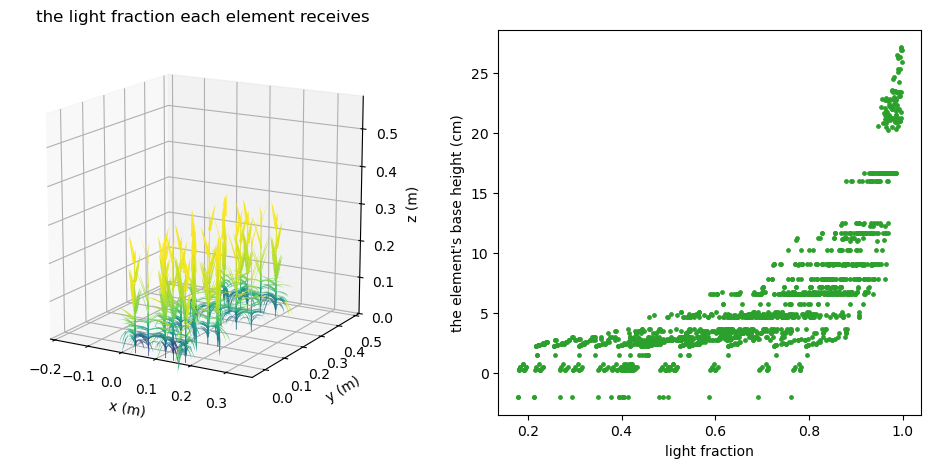

In [16]:
def light_fraction(triangles, n_elements, extinction=0.5, column_width=0.05):
    centre = triangles.vertices.mean(axis=1)
    side = triangles.vertices[:, 1, :2] - triangles.vertices[:, 0, :2]
    other = triangles.vertices[:, 2, :2] - triangles.vertices[:, 0, :2]
    projected = 0.5 * np.abs(side[:, 0] * other[:, 1] - side[:, 1] * other[:, 0])
    _, column = np.unique(np.floor(centre[:, :2] / column_width).astype(int), axis=0, return_inverse=True)
    column = column.reshape(-1)
    above = np.array([projected[(column == column[i]) & (centre[:, 2] > centre[i, 2])].sum()
                      for i in range(len(projected))])
    fraction = np.exp(-extinction * above / column_width ** 2)
    areas = triangles.areas()
    total = triangles.per_owner(areas, n_elements)
    return np.where(total > 0, triangles.per_owner(fraction, n_elements, weights=areas) / np.where(total > 0, total, 1.),
                    0.)


triangles = architecture.triangles()
fraction = light_fraction(triangles, ds.n_nodes())
figure = plt.figure(figsize=(12, 5))
axes = figure.add_subplot(1, 2, 1, projection="3d")
draw(axes, triangles, colors=value_colors(fraction, limits=(0., 1.)), shade=False)
axes.set_title("the light fraction each element receives")
axes = figure.add_subplot(1, 2, 2)
green = np.asarray(ds.get("green_area")) > 0
axes.scatter(fraction[green], np.asarray(ds.get("z1"))[green] * 100, s=6, c="tab:green")
axes.set_xlabel("light fraction")
axes.set_ylabel("the element's base height (cm)");

`example/light_coupling.py` makes this toy light model a metafspm component (`ToyLight`). It runs in the plant model
after the shoot, and writes each element's light fraction and absorbed light on the DataStructure.

## 6. The comparison with the legacy, and the speed

`openalea.adel.comparison` runs the frozen legacy (`openalea.adel.legacy.adel_dynamic.AdelDyn`) and the port on the
same scenario. The tests in `test/comparison` compare the topology, the elements' lengths and areas, the anchor points
and every triangle, step by step, on one plant and on a stand of four plants. They agree to 1e-10 m.

Here are the two canopies side by side: four plants after 900 °Cd. The legacy's triangles are drawn as its turtle
placed them. The legacy's `update_geometry` then places each plant a second time: it translates the plant by its
position again, and rotates it by its azimuth's degrees read as radians.

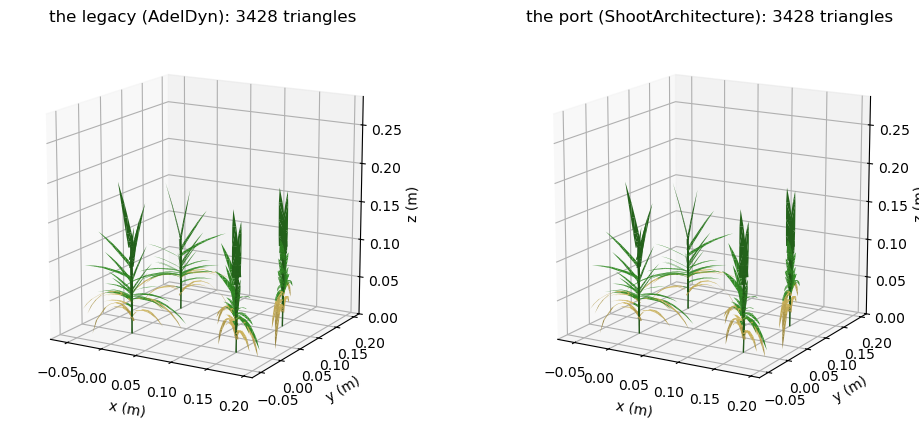

In [17]:
from openalea.adel.comparison.legacy_run import StandPlant, legacy_canopy, legacy_run
from openalea.adel.comparison.port_run import coleoptile_top, port_run

plants = [StandPlant(0., 0., 0., 0.), StandPlant(15., 0., 40., 30.), StandPlant(0., 12., 130., 60.),
          StandPlant(15., 12., 250., 15.)]
options = dict(n_steps=90, leaves="echap", n_sect=2, plants=plants, record_every=90)
legacy, port = legacy_run(**options), port_run(**options)
legacy_vertices, legacy_green = legacy_canopy(legacy.steps[-1], plants,
                                              [coleoptile_top(record) for record in port.steps[-1]])
port_triangles = port.scene.populations[0].instance.architecture.triangles()
port_green = np.asarray(port.scene.populations[0].data_structure.get("is_green"))

figure = plt.figure(figsize=(12, 5))
for k, (title, vertices, colors) in enumerate((("the legacy (AdelDyn)", legacy_vertices, state_colors(legacy_green)),
                                               ("the port (ShootArchitecture)", port_triangles.vertices,
                                                state_colors(port_green)[port_triangles.owner]))):
    axes = figure.add_subplot(1, 2, k + 1, projection="3d")
    draw(axes, vertices, triangle_colors=colors)
    axes.set_title(f"{title}: {len(vertices)} triangles")

The speed: 60 steps of both models on stands of 1 and 4 plants, with the geometry computed at every step, as a light
model coupled at each step needs it. The port's lead grows with the plants' size and number:
`example/comparison/profile_population.py` runs the full profile, up to 16 plants.

In [18]:
import sys
sys.path.insert(0, "../comparison")
from profile_population import legacy_time, port_time, stand

port_time(stand(1), 2)                                   # numba's compilations aside
rows = []
for n_plants in (1, 4):
    legacy_seconds, _ = legacy_time(stand(n_plants), 60)
    stepping, meshing, _ = port_time(stand(n_plants), 60)
    rows.append(dict(plants=n_plants, legacy=legacy_seconds, port=stepping + meshing,
                     speed_up=legacy_seconds / (stepping + meshing)))
pd.DataFrame(rows).round(2)

,plants,legacy,port,speed_up
0,1,1.81,0.76,2.39
1,4,3.40,0.52,6.53


## Where next

- `example/canopy.py`, `example/generated_plants.py`, `example/tillers.py` and `example/light_coupling.py`: the
  canopy, generated plants, the tillers and the light coupling above, as scripts;
- `example/comparison/`: the side-by-side drawing and the profile;
- the module documentation of `openalea.adel.architecture`: the structure, the variables, the coupling contract.

Adel's QuickStart notebook (`example/legacy/notebook`) still runs the legacy, with AdelWheat's R kinetics. These are
not ported: in metafspm, the organs' lengths come from development models.